In [ ]:
!pip install -q holidays
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip -o "/content/drive/MyDrive/탄소시계/탄소시계_1단계_데이터정리.zip" -d "/content/drive/MyDrive/탄소시계/"

unzip:  cannot find or open /content/drive/MyDrive/탄소시계/탄소시계_1단계_데이터정리.zip, /content/drive/MyDrive/탄소시계/탄소시계_1단계_데이터정리.zip.zip or /content/drive/MyDrive/탄소시계/탄소시계_1단계_데이터정리.zip.ZIP.


%cd "/content/drive/MyDrive/탄소시계/project"
!python scripts/01_prepare_data.py "/content/drive/MyDrive/탄소시계/2026_데이터분석_연구__데이터.xlsx"

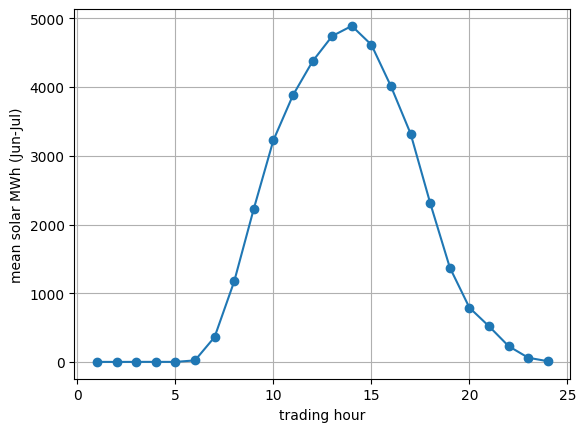

hour
6       23.0
7      363.0
8     1172.0
13    4743.0
14    4890.0
20     790.0
21     519.0
Name: mwh, dtype: float64


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
xl = "/content/drive/MyDrive/2026 데이터분석연구회/project/2026_데이터분석_연구_데이터.xlsx"
k = pd.read_excel(xl, sheet_name=0); k.columns = ['date','hour','fuel','cap','mwh']
k['date'] = pd.to_datetime(k['date'])
s = k[(k.fuel=='태양광') & (k.date.dt.month.isin([6,7]))].groupby('hour').mwh.mean()
s.plot(marker='o'); plt.xlabel('trading hour'); plt.ylabel('mean solar MWh (Jun-Jul)'); plt.grid(); plt.show()
print(s.round(0).loc[[6,7,8,13,14,20,21]])

In [ ]:
!pip install holidays
!python 01_prepare_data.py "2026_데이터분석_연구_데이터.xlsx"

python3: can't open file '/content/01_prepare_data.py': [Errno 2] No such file or directory


In [ ]:
"""
[1단계] 데이터 정리: 원본 4개 표 -> 분석용 CSV
실행:  python 01_prepare_data.py "2026_데이터분석_연구_데이터.xlsx"
결과:  ../data/clean/*.csv  (모두 GitHub 25MB 제한 안)

코드는 6개 구역(A~F)으로 나뉘어 있고, 위에서 아래로 한 번만 실행하면 됩니다.
  A. KPX 시간별 자료 읽기와 검사      (데이터 1)
  B. IPCC 배출계수 표 숫자로 바꾸기   (데이터 4)
  C. 연료원 대응표 만들기             (KPX 연료원 -> IPCC 기술 -> 계수)
  D. 시간별 탄소집약도 계산           (핵심 계산)
  E. EPSIS 설비용량과 비교            (데이터 2, 범위 검증)
  F. 에너지공단 제품 표 정리          (데이터 3)
"""
import sys, re
from pathlib import Path
import numpy as np
import pandas as pd
import holidays

# 코랩/노트북 환경인지 감지하여, sys.argv 대신 정의된 변수 xl를 우선 활용
is_ipython = 'ipykernel' in sys.modules
if is_ipython:
    default_xlsx = xl if 'xl' in globals() else "/content/drive/MyDrive/2026 데이터분석연구회/project/2026_데이터분석_연구__데이터.xlsx"
else:
    default_xlsx = sys.argv[1] if len(sys.argv) > 1 else "2026_데이터분석_연구__데이터.xlsx"

XLSX = Path(default_xlsx)
OUT = Path(__file__).resolve().parent.parent / "data" / "clean" if "__file__" in globals() else Path("data/clean")
OUT.mkdir(parents=True, exist_ok=True)

# ---- 팀이 정해야 하는 값 (지금은 비워 둠) -------------------------------------
KEA_EF_G_PER_KWH = None   # 에너지공단 라벨의 CO2 환산계수(g/kWh). 확인되면 숫자로 채움
NOON_HOURS = [13, 14]     # 거래시간 13,14 = 12~14시  (거래시간 h = (h-1)시~h시)
EVE_HOURS = [20, 21]      # 거래시간 20,21 = 19~21시
# -------------------------------------------------------------------------------

sheets = pd.ExcelFile(XLSX).sheet_names
print("탭:", sheets)

# =============================== A. KPX 읽기와 검사 =============================
kpx = pd.read_excel(XLSX, sheet_name=sheets[0])
kpx.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]       # 영문 열 이름으로 통일
kpx["date"] = pd.to_datetime(kpx["date"])

# 검사: 하루 24시간이 모두 있는지, (날짜,시간,연료원) 중복이 없는지, 빈 값이 없는지
assert kpx["date"].nunique() == 365, "날짜 수가 365가 아님"
assert set(kpx["hour"].unique()) == set(range(1, 25)), "거래시간이 1~24가 아님"
assert not kpx.duplicated(["date", "hour", "fuel"]).any(), "중복 행이 있음"
assert not kpx.isna().any().any(), "빈 값이 있음"
n_neg = int((kpx["mwh"] < 0).sum())
print(f"KPX 행 {len(kpx):,} | 연료원 {kpx['fuel'].nunique()}종 | 음수 {n_neg}건")
kpx["mwh"] = kpx["mwh"].clip(lower=0)                           # 음수는 0 처리(계획서 3번)

# 날짜 구분: 계절, 평일/휴일(주말+공휴일)
kr_holidays = holidays.country_holidays("KR", years=2025)       # 공식 달력과 꼭 대조할 것
m = kpx["date"].dt.month
kpx["month"] = m
kpx["season"] = np.select([m.isin([3, 4, 5]), m.isin([6, 7, 8]), m.isin([9, 10, 11])],
                          ["봄", "여름", "가을"], "겨울")
is_off = (kpx["date"].dt.dayofweek >= 5) | kpx["date"].dt.date.isin(kr_holidays.keys())
kpx["day_type"] = np.where(is_off, "휴일", "평일")

# =============================== B. IPCC 표 =====================================
ip = pd.read_excel(XLSX, sheet_name=sheets[3], header=None)
def parse_triplet(x):
    """'740/820/910' -> (740, 820, 910) / '0' -> (0,0,0) / 'n.a.' -> (nan,nan,nan)"""
    s = str(x).strip()
    try:
        if "/" in s:
            a, b, c = [float(v) for v in s.split("/")]
            return a, b, c
        v = float(s); return v, v, v
    except ValueError:                      # 'n.a.', 'Min/Median/Max' 같은 글자는 빈 값 처리
        return np.nan, np.nan, np.nan
rows = []
for _, r in ip.iterrows():
    name, direct, life = r[0], r[1], r[5]
    if pd.isna(direct) or pd.isna(life):        # 구분 제목·각주 행 건너뜀
        continue
    d, l = parse_triplet(direct), parse_triplet(life)
    if np.isnan(l[1]):                      # 전과정 값이 숫자가 아니면(머리글 행) 건너뜀
        continue
    rows.append([str(name).strip(), *d, *l])
ipcc = pd.DataFrame(rows, columns=["tech", "direct_min", "direct_med", "direct_max",
                                   "life_min", "life_med", "life_max"])
ipcc.to_csv(OUT / "ipcc_factors.csv", index=False, encoding="utf-8-sig")
print("IPCC 기술 수:", len(ipcc))
ipcc_i = ipcc.set_index("tech")

# =============================== C. 연료원 대응표 ===============================
# (KPX 연료원, IPCC 기술, EPSIS 열, 계산에 넣는가, 비고)
M = [
 ("원자력", "Nuclear", "원자력", True, ""),
 ("유연탄", "Coal—PC", "유연탄", True, ""),
 ("무연탄", "Coal—PC", "무연탄", True, "IPCC는 석탄 종류를 나누지 않음"),
 ("IGCC", "Coal—PC", "석탄가스화", True, "석탄 계수로 보수적으로 적용(설비 작음)"),
 ("LNG", "Gas—Combined Cycle", "LNG", True, ""),
 ("LPG", "Gas—Combined Cycle", "(확인필요)", True, "가스 계수 가정, 비중 작음"),
 ("연료전지", "Gas—Combined Cycle", "연료전지", True, "가스 계수 가정"),
 ("부생가스", "Gas—Combined Cycle", "기타", True, "가스 계수 가정(EPSIS 비고: 기타에 포함)"),
 ("가스압", None, "기타", True, "연소 없는 차압 발전 -> 0으로 둠"),
 ("경유", None, "유류", True, "IPCC에 없음 -> 보조 출처 값"),
 ("중유", None, "유류", True, "IPCC에 없음 -> 보조 출처 값"),
 ("태양광", "Solar PV—utility", "태양", True, ""),
 ("풍력", "Wind onshore", "풍력", True, "육상 기준"),
 ("수력", "Hydropower", "수력", True, "IPCC 최대값 2200은 저수지 메탄 사례"),
 ("소수력", "Hydropower", "수력", True, ""),
 ("해양에너지", "Ocean", "해양", True, ""),
 ("바이오매스", "Biomass—dedicated", "바이오", True, "직접배출은 생물기원이라 0으로 둠"),
 ("바이오가스", "Biomass—dedicated", "바이오", True, ""),
 ("바이오SRF", "Biomass—dedicated", "바이오", True, ""),
 ("바이오중유", "Biomass—dedicated", "바이오", True, ""),
 ("매립가스", "Biomass—dedicated", "바이오", True, ""),
 ("양수", None, "양수", False, "저장 방전분, 충전 전력이 기록되지 않아 제외"),
 ("급전가능 재생에너지", None, "(확인필요)", False, "구성 불명 -> 제외"),
 ("기타", None, "기타", False, "구성 불명 -> 제외"),
 ("폐기물", None, "폐기물", False, "IPCC에 없음 -> 제외"),
 ("전기저장장치(비중앙)", None, "(확인필요)", False, "연중 일부 기간만 있음 -> 제외"),
]
fm = pd.DataFrame(M, columns=["fuel", "ipcc_tech", "epsis_col", "include", "note"])
# 보조 값(IPCC에 없는 연료): 전과정 720 / 직접배출은 국내 문헌 값(경유 603, 중유 689)
manual = {"경유": dict(life=(720, 720, 720), direct=603),
          "중유": dict(life=(720, 720, 720), direct=689),
          "가스압": dict(life=(0, 0, 0), direct=0)}
fl = []
for _, r in fm.iterrows():
    if r.fuel in manual:
        lo, md, hi = manual[r.fuel]["life"]; dr = manual[r.fuel]["direct"]
        fl.append((lo, md, hi, dr, dr, dr))
    elif pd.notna(r.ipcc_tech):
        t = ipcc_i.loc[r.ipcc_tech]
        d = t.direct_med if not np.isnan(t.direct_med) else 0.0   # n.a.(바이오)는 0
        dmin = t.direct_min if not np.isnan(t.direct_min) else 0.0
        dmax = t.direct_max if not np.isnan(t.direct_max) else 0.0
        fl.append((t.life_min, t.life_med, t.life_max, dmin, d, dmax))
    else:
        fl.append((np.nan,) * 6)
fm[["f_min", "f_mid", "f_max", "dir_min", "f_dir", "dir_max"]] = pd.DataFrame(fl, index=fm.index)
assert set(fm.fuel) == set(kpx.fuel.unique()), "KPX 연료원과 대응표가 다름"
fm.drop(columns=["dir_min", "dir_max"]).to_csv(OUT / "fuel_map.csv", index=False, encoding="utf-8-sig")

# =============================== D. 탄소집약도 계산 =============================
inc = kpx.merge(fm[["fuel", "include", "f_min", "f_mid", "f_max", "f_dir"]], on="fuel")
tot_all = inc["mwh"].sum()
excl_share = inc.loc[~inc["include"], "mwh"].sum() / tot_all * 100
inc = inc[inc["include"]].copy()
print(f"계산 제외 연료 비중: {excl_share:.2f}%")
for col, name in [("f_min", "ci_min"), ("f_mid", "ci_mid"), ("f_max", "ci_max"), ("f_dir", "ci_direct")]:
    inc["em_" + name] = inc["mwh"] * inc[col]                      # 연료원별 배출량 = 거래량 x 계수
inc["solar_mwh"] = np.where(inc["fuel"] == "태양광", inc["mwh"], 0.0)
EM = ["em_ci_min", "em_ci_mid", "em_ci_max", "em_ci_direct"]

def intensity(g):
    """묶음 안의 (배출량 합) / (거래량 합) = 가중평균 탄소집약도"""
    s = g[EM + ["mwh", "solar_mwh"]].sum()
    out = {n: s["em_" + n] / s["mwh"] if s["mwh"] > 0 else 0 for n in ["ci_min", "ci_mid", "ci_max", "ci_direct"]}
    out.update(total_mwh=s["mwh"], solar_share=s["solar_mwh"] / s["mwh"] * 100 if s["mwh"] > 0 else 0)
    return pd.Series(out)

# D-1 날짜x시간(8,760행)
dh = (inc.groupby(["date", "hour", "month", "season", "day_type"], sort=True)
         .apply(intensity, include_groups=False).reset_index())
dh["date"] = dh["date"].dt.strftime("%Y-%m-%d")
dh.round(3).to_csv(OUT / "ci_dayhour.csv", index=False, encoding="utf-8-sig")

# D-2 계절 x 평일/휴일 x 시간 (평균 곡선 + 일별 변동 띠)
sh = (inc.groupby(["season", "day_type", "hour"]).apply(intensity, include_groups=False).reset_index())
band = (dh.groupby(["season", "day_type", "hour"])["ci_mid"]
          .agg(ci_mid_p25=lambda x: x.quantile(.25), ci_mid_p75=lambda x: x.quantile(.75),
               ci_mid_dmin="min", ci_mid_dmax="max", n_days="size").reset_index())
sh = sh.merge(band, on=["season", "day_type", "hour"]).drop(columns=["solar_share"])
sh.round(2).to_csv(OUT / "ci_season_hour.csv", index=False, encoding="utf-8-sig")

# D-3 월 x 시간 (히트맵용)
mh = inc.groupby(["month", "hour"]).apply(intensity, include_groups=False).reset_index()
mh.round(2).to_csv(OUT / "ci_month_hour.csv", index=False, encoding="utf-8-sig")

# D-4 월별 정오-저녁 격차와 정오 태양광 비중 (작은 질문 3)
def noon_eve(g):
    a = intensity(g[g["hour"].isin(NOON_HOURS)]); b = intensity(g[g["hour"].isin(EVE_HOURS)])
    return pd.Series(dict(noon_ci=a.ci_mid, eve_ci=b.ci_mid,
                          gap_pct=(b.ci_mid - a.ci_mid) / b.ci_mid * 100 if b.ci_mid > 0 else 0,
                          noon_solar_share=a.solar_share))
mg = inc.groupby("month").apply(noon_eve, include_groups=False).reset_index()
mg.round(2).to_csv(OUT / "ci_month_gap.csv", index=False, encoding="utf-8-sig")
print("월별 격차-태양광 비중 상관:", round(mg["gap_pct"].corr(mg["noon_solar_share"]), 2))

# 확인용 요약(예비 결과)
allh = inc.groupby("hour").apply(intensity, include_groups=False)
print(f"연평균 CI(중앙) {inc['em_ci_mid'].sum()/inc['mwh'].sum():.1f} | 최저 거래시간 {allh.ci_mid.idxmin()} "
      f"({allh.ci_mid.min():.1f}) | 최고 거래시간 {allh.ci_mid.idxmax()} ({allh.ci_mid.max():.1f})")
noon = allh.loc[NOON_HOURS, "ci_mid"].mean(); eve = allh.loc[EVE_HOURS, "ci_mid"].mean()
print(f"정오 {noon:.1f} vs 저녁 {eve:.1f} -> 이동분 기준 감소 {(eve-noon)/eve*100:.1f}%")

# =============================== E. EPSIS 설비용량 비교 ==========================
ep = pd.read_excel(XLSX, sheet_name=sheets[1], header=None)
cols = ["기간", "회원구분", "급전방식", "사업구분", "지역", "원자력", "유연탄", "무연탄", "유류", "LNG", "양수",
        "연료전지", "석탄가스화", "태양", "풍력", "수력", "해양", "바이오", "폐기물", "기타", "합계"]
ep = ep.iloc[2:].copy(); ep.columns = cols
ep = ep[ep["기간"].astype(str).str.startswith("2025/")].copy()
ep["month"] = ep["기간"].astype(str).str[-2:].astype(int)
for c in cols[5:]: ep[c] = pd.to_numeric(ep[c], errors="coerce")
# KPX 월말 설비용량(그 달 마지막 날 24시간 평균)을 같은 열 이름으로 묶음
epsis_col = fm.set_index("fuel")["epsis_col"].to_dict()
k = kpx.copy(); k["col"] = k["fuel"].map(epsis_col)
last = k.groupby("month")["date"].transform("max")
kl = k[k["date"] == last]
kc = kl.groupby(["month", "col", "fuel"])["cap_mw"].mean().groupby(["month", "col"]).sum().reset_index()
cmp_rows = []
for col in ["원자력", "유연탄", "무연탄", "LNG", "양수", "연료전지", "석탄가스화", "태양", "풍력", "수력", "해양", "바이오", "폐기물"]:
    for _, r in ep.iterrows():
        v = kc[(kc.month == r.month) & (kc["col"] == col)]["cap_mw"].sum()
        cmp_rows.append((r.month, col, v, r[col], v / r[col] * 100 if r[col] else np.nan))
tot_kpx = kl.groupby("month")["cap_mw"].sum() / 1  # 월말 하루의 24시간 설비합 -> 아래서 24로 나눔
tot_kpx = (kl.groupby("month")["cap_mw"].sum() / 24)
for _, r in ep.iterrows():
    cmp_rows.append((r.month, "합계", tot_kpx[r.month], r["합계"], tot_kpx[r.month] / r["합계"] * 100))
cov = pd.DataFrame(cmp_rows, columns=["month", "group", "kpx_cap_mw", "epsis_cap_mw", "kpx_share_pct"])
cov.round(1).to_csv(OUT / "capacity_coverage.csv", index=False, encoding="utf-8-sig")
s12 = cov[(cov.month == 12) & (cov.group == "태양")].iloc[0]
print(f"2025년 12월 태양광 설비: KPX {s12.kpx_cap_mw:,.0f}MW / EPSIS {s12.epsis_cap_mw:,.0f}MW = {s12.kpx_share_pct:.1f}%")

# =============================== F. 에너지공단 제품 표 ===========================
kea = pd.read_excel(XLSX, sheet_name=sheets[2], header=None)
hdr_rows = kea.index[kea[1].astype(str).eq("기자재명")].tolist() + [len(kea)]
spec = {"전기세탁기(일반)": ("1회", "연간"), "전기밥솥": ("1시간", "연간"),
        "의류건조기": ("1회", "연간"), "전기냉방기": ("1시간", "월간")}
def num(s): return pd.to_numeric(s.astype(str).str.extract(r"([ᄀ-ᇿ㄰-㆏ꥠ-꥿ힰ-ퟆퟷ-ퟻ가-힣a-zA-Z\d.]+)")[0], errors="coerce")
tidy = []
for a, b in zip(hdr_rows[:-1], hdr_rows[1:]):
    blk = kea.iloc[a + 1:b].copy(); blk.columns = kea.iloc[a].tolist()
    cat = blk.iloc[0, 1]; use_unit, cost_period = spec[cat]
    t = pd.DataFrame({"category": cat, "model": blk.iloc[:, 2].astype(str).str.strip(),
                      "grade": blk.iloc[:, 3].astype(str).str.strip().replace({"최저소비효율기준미달": "기준미달"}),
                      "capacity_value": num(blk.iloc[:, 5]), "capacity_name": kea.iloc[a, 5],
                      "co2_per_use": num(blk.iloc[:, 6]), "use_unit": use_unit,
                      "cost": num(blk.iloc[:, 7]), "cost_period": cost_period})
    n_raw = len(t); t = t.drop_duplicates("model", keep="first")   # 모델명 중복 제거
    t.attrs["n_raw"] = n_raw; tidy.append(t)
kea_clean = pd.concat(tidy, ignore_index=True)
kea_clean.to_csv(OUT / "kea_models_clean.csv", index=False, encoding="utf-8-sig")
pres = []
for t in tidy:
    c = t["co2_per_use"].dropna(); cap = t["capacity_value"].dropna()
    row = dict(category=t["category"].iloc[0], use_unit=t["use_unit"].iloc[0], n_raw=t.attrs["n_raw"], n_clean=len(t),
               co2_median=c.median(), co2_p25=c.quantile(.25), co2_p75=c.quantile(.75), co2_min=c.min(), co2_max=c.max(),
               capacity_name=t["capacity_name"].iloc[0], capacity_median=cap.median())
    if KEA_EF_G_PER_KWH:   # 환산계수가 정해지면 kWh도 계산
        for k_ in ["co2_median", "co2_p25", "co2_p75"]:
            row[k_.replace("co2", "kwh")] = row[k_] / KEA_EF_G_PER_KWH
    pres.append(row)
pd.DataFrame(pres).round(2).to_csv(OUT / "activity_presets.csv", index=False, encoding="utf-8-sig")
print(pd.DataFrame(pres)[["category", "use_unit", "n_raw", "n_clean", "co2_median", "co2_p25", "co2_p75"]].to_string(index=False))
print("완료:", sorted(p.name for p in OUT.glob("*.csv")))

탭: ['한국전력거래소_연료원별 ', '전력거래량(전력시장·PPA)_ 연료원별(전력통계정보시스템', '한국에너지공단_에너지소비효율등급제도 기기부문 제품정보_2', '발전원별 온실가스 배출계수_(IPCC AR5 WGIII ']
KPX 행 224,928 | 연료원 26종 | 음수 61건
IPCC 기술 수: 17
계산 제외 연료 비중: 1.18%
월별 격차-태양광 비중 상관: 0.93
연평균 CI(중앙) 414.9 | 최저 거래시간 13 (387.0) | 최고 거래시간 21 (429.5)
정오 388.9 vs 저녁 429.3 -> 이동분 기준 감소 9.4%
2025년 12월 태양광 설비: KPX 10,834MW / EPSIS 30,761MW = 35.2%
 category use_unit  n_raw  n_clean  co2_median  co2_p25  co2_p75
전기세탁기(일반)       1회    779      774        40.0     33.0     48.0
     전기밥솥      1시간   2951     2840        22.0     17.0     29.0
    의류건조기       1회    942      937       750.0    479.0    856.0
    전기냉방기      1시간   3104     2906       384.5    258.0    439.0
완료: ['activity_presets.csv', 'capacity_coverage.csv', 'ci_dayhour.csv', 'ci_month_gap.csv', 'ci_month_hour.csv', 'ci_season_hour.csv', 'fuel_map.csv', 'ipcc_factors.csv', 'kea_models_clean.csv']


In [ ]:
"""
[피드백 반영] 지도교수 피드백 2가지를 데이터로 확인
 (1) 음수 61건: 어떤 값인지, 0 처리 전후로 결과가 달라지는지
 (2) 감소율의 분모: 이동분 / 저녁 19~21시 / 하루 전체 3가지로 나눠 계산
실행: python 02_feedback_checks.py "2026_데이터분석_연구__데이터.xlsx"   (01번 스크립트를 먼저 실행해 fuel_map.csv가 있어야 함)
결과: ../data/clean/negative_check.csv, shift_denominators.csv
"""
import sys
from pathlib import Path
import numpy as np, pandas as pd, holidays

# 코랩/노트북 환경인지 감지하여, sys.argv 대신 정의된 변수 xl를 우선 활용
is_ipython = 'ipykernel' in sys.modules
if is_ipython:
    default_xlsx = xl if 'xl' in globals() else "/content/drive/MyDrive/2026 데이터분석연구회/project/2026_데이터분석_연구_데이터.xlsx"
else:
    default_xlsx = sys.argv[1] if len(sys.argv) > 1 else "2026_데이터분석_연구__데이터.xlsx"

XLSX = Path(default_xlsx)
OUT = Path(__file__).resolve().parent.parent / "data" / "clean" if "__file__" in globals() else Path("data/clean")
NOON, EVE = [13, 14], [20, 21]

kpx = pd.read_excel(XLSX, sheet_name=0); kpx.columns = ["date", "hour", "fuel", "cap", "mwh"]
kpx["date"] = pd.to_datetime(kpx["date"])
fm = pd.read_csv(OUT / "fuel_map.csv")
F_MID = fm.set_index("fuel")["f_mid"].to_dict()
INCL = fm.set_index("fuel")["include"].to_dict()

# ---------------------------------------------------------------- (1) 음수 확인
neg = kpx[kpx.mwh < 0]
a = kpx[kpx.fuel == "급전가능 재생에너지"]
print("음수 행", len(neg), "| 연료원:", neg.fuel.unique().tolist())
print(f"그 연료의 전체 {len(a):,}행 중 음수 {len(neg)}행 | 음수 합 {neg.mwh.sum():.1f} MWh | 같은 연료 양수 합 {a[a.mwh>0].mwh.sum():,.0f} MWh")
print("음수 값 평균 %.2f, 최소 %.2f MWh | 거래시간 1~7시 구간 %d건 / 61건" % (neg.mwh.mean(), neg.mwh.min(), neg.hour.between(1, 7).sum()))

def run(include_adjustable, clip, f_adj=48.0):
    d = kpx.copy()
    d["f"] = d.fuel.map(F_MID)
    d["inc"] = d.fuel.map(INCL)
    if include_adjustable:
        d.loc[d.fuel == "급전가능 재생에너지", ["f", "inc"]] = [f_adj, True]
    if clip: d["mwh"] = d.mwh.clip(lower=0)
    d = d[d.inc.astype(bool)].copy()
    d["em"] = d.mwh * d.f
    g = d.groupby(["date", "hour"])[["em", "mwh"]].sum()
    g["ci"] = g.em / g.mwh
    h = d.groupby("hour")[["em", "mwh"]].sum(); hci = h.em / h.mwh
    noon = h.loc[NOON, "em"].sum() / h.loc[NOON, "mwh"].sum(); eve = h.loc[EVE, "em"].sum() / h.loc[EVE, "mwh"].sum()
    return dict(annual_ci=d.em.sum() / d.mwh.sum(), min_hour=int(hci.idxmin()), min_ci=hci.min(), max_hour=int(hci.idxmax()),
                max_ci=hci.max(), noon_ci=noon, eve_ci=eve, moved_reduction_pct=(eve - noon) / eve * 100), g["ci"]

S = [("S0 기본: 급전가능 제외 + 음수 0 처리", False, True, 48), ("S1 급전가능 제외 + 음수 그대로", False, False, 48),
     ("S2 급전가능 포함(계수 48) + 음수 0 처리", True, True, 48), ("S3 급전가능 포함(계수 48) + 음수 그대로", True, False, 48),
     ("S4 급전가능 포함(계수 230) + 음수 0 처리", True, True, 230), ("S5 급전가능 포함(계수 490) + 음수 0 처리", True, True, 490)]
rows, cis = [], {}
for name, inc, clip, fadj in S:
    r, ci = run(inc, clip, fadj); r["scenario"] = name; rows.append(r); cis[name] = ci
res = pd.DataFrame(rows)[["scenario", "annual_ci", "min_hour", "min_ci", "max_hour", "max_ci", "noon_ci", "eve_ci", "moved_reduction_pct"]]
d01 = (cis[S[0][0]] - cis[S[1][0]]).abs().max(); d23 = (cis[S[2][0]] - cis[S[3][0]]).abs().max()
res["max_abs_diff_vs_pair(gCO2/kWh)"] = [0.0, d01, 0.0, d23, np.nan, np.nan]
res.round(4).to_csv(OUT / "negative_check.csv", index=False, encoding="utf-8-sig")
print(res.round(3).to_string(index=False))
print(f"\n0 처리 전후 (날짜x시간) 탄소집약도 최대 차이: 제외 시 {d01:.6f}, 포함 시 {d23:.6f} g/kWh")

# ---------------------------------------------------------------- (2) 분모 3가지
d = kpx.copy(); d["mwh"] = d.mwh.clip(lower=0); d["f"] = d.fuel.map(F_MID); d["inc"] = d.fuel.map(INCL)
d = d[d.inc.astype(bool)].copy(); d["em"] = d.mwh * d.f
kr = holidays.country_holidays("KR", years=2025)
off = (d.date.dt.dayofweek >= 5) | d.date.dt.date.isin(kr.keys())
m = d.date.dt.month
d["season"] = np.select([m.isin([3, 4, 5]), m.isin([6, 7, 8]), m.isin([9, 10, 11])], ["봄", "여름", "가을"], "겨울")
d["day_type"] = np.where(off, "휴일", "평일")

def scope_table(name, sub):
    h = sub.groupby("hour")[["em", "mwh"]].sum()
    ci_h = h.em / h.mwh
    E = h.mwh / h.mwh.sum()                                  # 시간별 사용 비중(시장 거래량 모양을 사용 패턴 대용으로 사용)
    noon = h.loc[NOON, "em"].sum() / h.loc[NOON, "mwh"].sum(); eve = h.loc[EVE, "em"].sum() / h.loc[EVE, "mwh"].sum()
    gap = eve - noon
    out = []
    for p in (0.10, 0.20, 0.30):
        moved = gap / eve                                        # (1) 이동한 전력의 원래 배출 기준(p와 무관)
        evening = p * gap / eve                                  # (2) 저녁 19~21시 총 배출 기준
        share_eve = E.loc[EVE].sum()
        daily_actual = p * share_eve * gap / (E * ci_h).sum()    # (3) 하루 전체, 시장 거래량 모양 패턴
        daily_uniform = p * (len(EVE) / 24) * gap / ci_h.mean()  # (3′) 하루 전체, 24시간 고르게 사용
        out.append(dict(scope=name, p_pct=int(p * 100), noon_ci=noon, eve_ci=eve, moved_pct=moved * 100, evening_pct=evening * 100,
                        daily_actual_pct=daily_actual * 100, daily_uniform_pct=daily_uniform * 100, evening_share_of_day_pct=share_eve * 100))
    return out
tab = scope_table("연간", d)
for s in ["봄", "여름", "가을", "겨울"]:
    tab += scope_table(f"{s} 평일", d[(d.season == s) & (d.day_type == "평일")])
den = pd.DataFrame(tab)
den.round(3).to_csv(OUT / "shift_denominators.csv", index=False, encoding="utf-8-sig")
print("\n[감소율 분모 3가지 - 연간]"); print(den[den.scope == "연간"].round(3).to_string(index=False))
print("\n[봄 평일, 30% 이동]"); print(den[(den.scope == "봄 평일") & (den.p_pct == 30)].round(3).to_string(index=False))

# ---------------------------------------------------------------- (3) 효과의 크기를 현실적으로 보기
print("\n================ (3) 효과 크기 ==============")
h_all = d.groupby("hour")[["em", "mwh"]].sum()
noon_all = h_all.loc[NOON, "em"].sum() / h_all.loc[NOON, "mwh"].sum()
eve_all = h_all.loc[EVE, "em"].sum() / h_all.loc[EVE, "mwh"].sum()
gap = eve_all - noon_all                                                 # g/kWh = kg/MWh
print(f"1kWh를 저녁->정오로 옮기면 약 {gap:.1f} g CO2eq 감소 (연간 평균) | 같은 1kWh를 아예 안 쓰면 약 {eve_all:.0f} g 감소")
print(f"=> 옮기기의 효과는 줄이기의 약 {gap/eve_all*100:.1f}%")
E_eve_mwh = d[d.hour.isin(EVE)].mwh.sum()
tot_em = d.em.sum()
for p in (0.1, 0.3):
    saved_t = p * E_eve_mwh * gap / 1000
    print(f"전국(시장 거래 기준) 저녁 19~21시 전력의 {int(p*100)}%를 옮기면 연 약 {saved_t:,.0f} tCO2eq, 시장 거래 전체 배출의 {saved_t*1000/tot_em*100:.3f}%")
spring_wd = d[(d.season == "봄") & (d.day_type == "평일")]; sh_ = spring_wd.groupby("hour")[["em", "mwh"]].sum()
print("봄 평일: 1kWh당 %.1f g" % (sh_.loc[EVE, "em"].sum()/sh_.loc[EVE, "mwh"].sum() - sh_.loc[NOON, "em"].sum()/sh_.loc[NOON, "mwh"].sum()))

# 날짜별 변동: 그날 저녁 대비, 07~22시(거래시간 8~22) 중 가장 깨끗한 시간으로 옮기면
g = d.groupby(["date", "hour", "season", "day_type"])[["em", "mwh"]].sum().reset_index(); g["ci"] = g.em / g.mwh
rows = []
for dt, x in g.groupby("date"):
    ev = x[x.hour.isin(EVE)]; eve_ci = ev.em.sum() / ev.mwh.sum()
    nn = x[x.hour.isin(NOON)]; noon_ci = nn.em.sum() / nn.mwh.sum()
    w = x[x.hour.between(8, 22)]; b = w.loc[w.ci.idxmin()]
    rows.append(dict(date=dt.strftime("%Y-%m-%d"), season=x.season.iloc[0], day_type=x.day_type.iloc[0], eve_ci=eve_ci, noon_ci=noon_ci,
                     best_hour=int(b.hour), best_ci=b.ci, red_to_noon_pct=(eve_ci-noon_ci)/eve_ci*100, red_to_best_pct=(eve_ci-b.ci)/eve_ci*100))
dp = pd.DataFrame(rows); dp.round(3).to_csv(OUT / "daily_potential.csv", index=False, encoding="utf-8-sig")
q = dp[["red_to_noon_pct", "red_to_best_pct"]].quantile([.1, .5, .9]).round(1); q.index = ["하위10%", "중앙값", "상위10%"]
print("\n[날짜별 이동분 감소율: 저녁 -> 정오 / 저녁 -> 07~22시 중 가장 깨끗한 시간]"); print(q.to_string())
print("정오로 옮겨도 오히려 더 더러운 날(감소율<0):", int((dp.red_to_noon_pct < 0).sum()), "일 /", len(dp))
print("\n[계절 x 평일/휴일 중앙값(저녁->정오 %)]"); print(dp.groupby(["season", "day_type"]).red_to_noon_pct.median().round(1).unstack().to_string())
print("\n[상위 5일]"); print(dp.sort_values("red_to_noon_pct", ascending=False).head(5)[["date", "season", "day_type", "eve_ci", "noon_ci", "red_to_noon_pct"]].round(1).to_string(index=False))

음수 행 61 | 연료원: ['급전가능 재생에너지']
그 연료의 전체 8,760행 중 음수 61행 | 음수 합 -70.7 MWh | 같은 연료 양수 합 888,323 MWh
음수 값 평균 -1.16, 최소 -3.68 MWh | 거래시간 1~7시 구간 55건 / 61건
                    scenario  annual_ci  min_hour  min_ci  max_hour  max_ci  noon_ci  eve_ci  moved_reduction_pct  max_abs_diff_vs_pair(gCO2/kWh)
    S0 기본: 급전가능 제외 + 음수 0 처리    414.894        13 387.006        21 429.490  388.946 429.336                9.408                           0.000
         S1 급전가능 제외 + 음수 그대로    414.894        13 387.006        21 429.490  388.946 429.336                9.408                           0.000
 S2 급전가능 포함(계수 48) + 음수 0 처리    414.292        13 386.248        21 428.961  388.180 428.802                9.473                           0.000
  S3 급전가능 포함(계수 48) + 음수 그대로    414.292        13 386.248        21 428.961  388.180 428.802                9.473                           0.028
S4 급전가능 포함(계수 230) + 음수 0 처리    414.590        13 386.655        21 429.214  388.589 429.057                9.432       